In [2]:
import pandas
import os
import itertools
import numpy as np
import nibabel as ni
import matplotlib.pyplot as plt
import seaborn as sns
from glob import glob
from scipy import stats
from scipy.io import loadmat
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn import model_selection, linear_model
from nilearn import image, plotting
from mpl_toolkits.mplot3d import Axes3D
import warnings
warnings.filterwarnings('ignore')

In [3]:
# Your git directory here:
git_dir = '/home/zeng/Documents/HippGPrj_Bhav/'
fig_dir = os.path.join(git_dir, 'Fig')

import sys
sys.path.insert(0,git_dir)
import HAP_Utils as hap

In [4]:
from importlib import reload
reload(hap)

<module 'HAP_Utils' from '/data1/zeng/Hippocampus_AP_Axis/HAP_Utils.py'>

In [7]:
wdir = '/data1/zeng/Hippocampus_AP_Axis/Data'

In [5]:
#wdir = os.path.join(git_dir, 'Data')

In [8]:
df = pandas.read_csv(os.path.join(wdir,'HCD_LS_2.0_subject_completeness_bh.csv'))
xp_L = pandas.read_csv(os.path.join(wdir,'G1_CTX_all_L.csv'), header=None)
xp_R = pandas.read_csv(os.path.join(wdir,'G1_CTX_all_R.csv'), header=None)
head_mv = pandas.read_csv(os.path.join(wdir,'head_mv_par_all.csv'))

In [9]:
Age=df['Age']
Sex=df['Sex'].replace(['F','M'],[-1,1])
Site=df['site'].replace(['Harvard','UMinn','UCLA','WashU'],[-2,-1,1,2])

In [10]:
mFD=head_mv['mFD']

In [11]:
Age_grp=Age.round(0)

In [12]:
Age_grp.unique()

array([ 6.,  7.,  8.,  9., 10., 11., 12., 13., 14., 15., 16., 17., 18.,
       19., 20., 21., 22.])

In [13]:
xp=pandas.concat([xp_L,xp_R,Sex,Site,mFD],axis=1,ignore_index=True)

In [53]:
cog='flanker'   #'psm_adj'    #'dccs_adj'   #'wm_adj'    #'flanker_adj'
df_cog=df[cog][~df[cog].isna()]
xp_cog=xp[~df[cog].isna()]
Age_grp_cog=Age_grp[~df[cog].isna()]

In [54]:
df_cog.index=range(len(df_cog))
xp_cog.index=range(len(xp_cog))
Age_grp_cog.index=range(len(Age_grp_cog))

In [ ]:
xp_cog

In [76]:
import importlib
importlib.reload(hap)

<module 'HAP_Utils' from '/data1/zeng/Hippocampus_AP_Axis/HAP_Utils.py'>

running PCA
transforming data
performing model cross-validation
balancing cross-validation by labels
start balanced cv


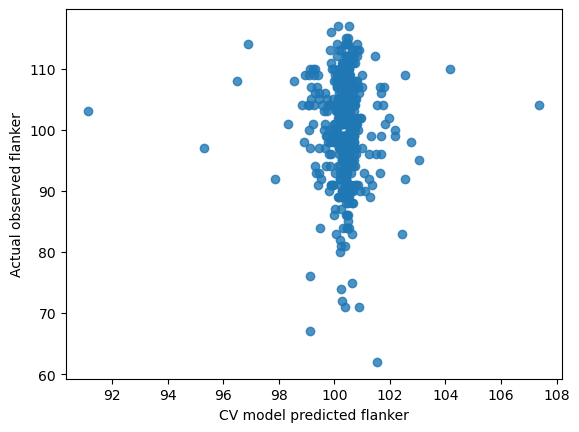

model cv score: r2 =  0.0011943102051186468
running final model
final model fit r2 =  0.007296311107783837


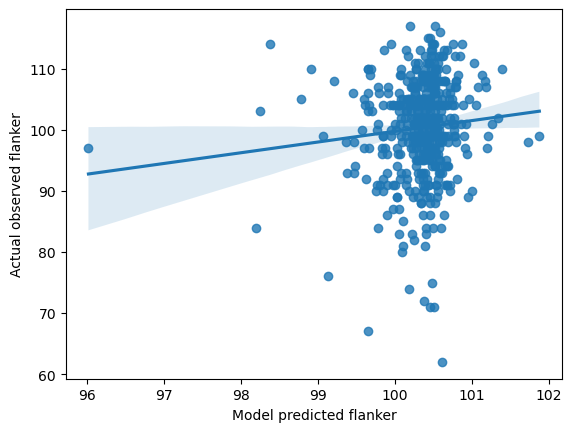

In [55]:
pcalr_out_NEW = hap.PCA_LR_pipeline(xp_cog.values, # X (Gradient Projection)
                                    df_cog, # cog/beh
                                    y_label=cog, #(y label to display)
                                    #pca = None, # use pca or not
                                    cv_strategy='balanced', #'balanced','score' # Show the 10-fold CV score
                                    illustrative=True, # Show plots
                                    test_gene_num = [1, 2, 5, 10, 20, 50],  # sanity check                                                    
                                    sanity_check_style = None,   # pos. and neg. separate
                                    cv_labels = Age_grp_cog, reverse_axes = False) 

In [56]:
pred_cog=pcalr_out_NEW['predicts']
obs_cog=pcalr_out_NEW['observes']
pred_obs_cog=pandas.DataFrame({'pred':pred_cog,'obs':obs_cog})

In [57]:
pred_obs_cog.to_csv(os.path.join(wdir,'Pred_cog_flanker.csv'),index=False)

In [59]:
filename=f"Pred_cog_{cog}.csv"

In [61]:
pred_obs_cog.to_csv(os.path.join(wdir,filename),index=False)

running PCA
transforming data
performing model cross-validation
balancing cross-validation by labels
start balanced cv


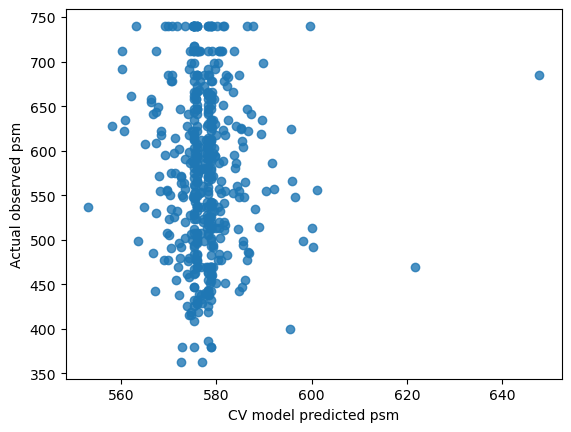

model cv score: r2 =  0.0009839554036340248
running final model
final model fit r2 =  0.01781236443302825


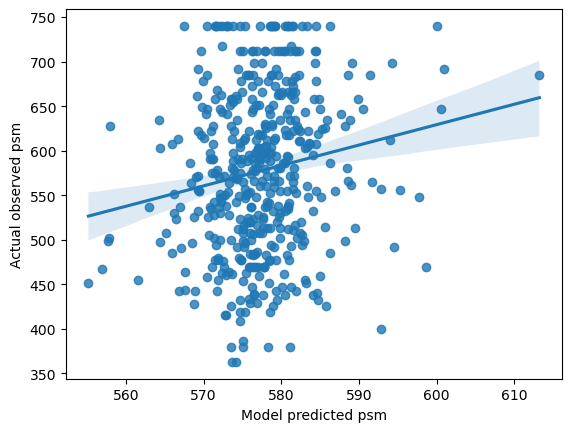

running PCA
transforming data
performing model cross-validation
balancing cross-validation by labels
start balanced cv


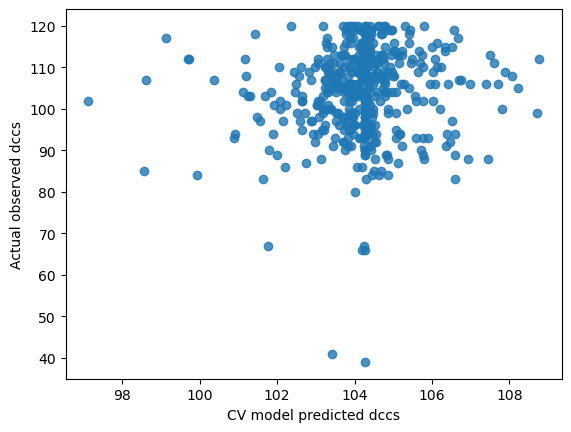

model cv score: r2 =  0.007425264035692774
running final model
final model fit r2 =  0.0968730391519812


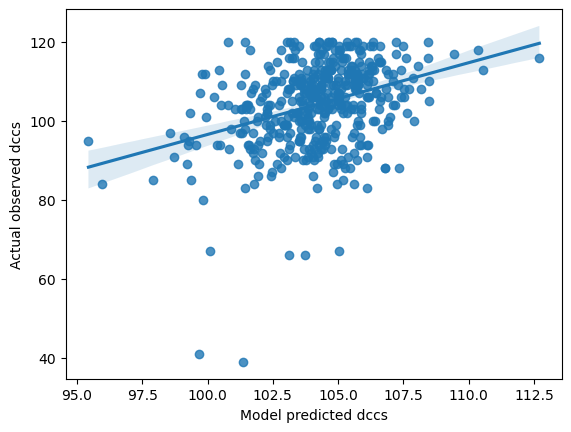

running PCA
transforming data
performing model cross-validation
balancing cross-validation by labels
start balanced cv


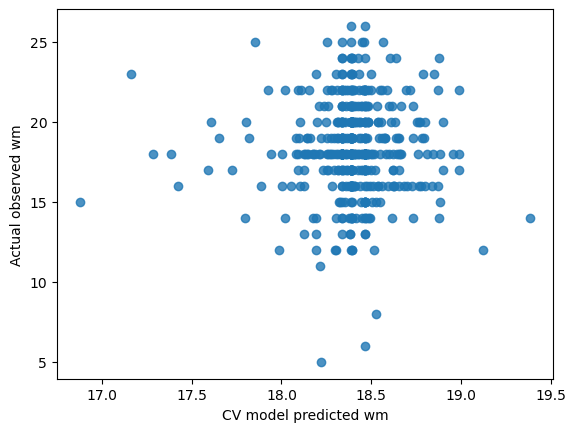

model cv score: r2 =  4.79686716268587e-05
running final model
final model fit r2 =  0.02307286526784602


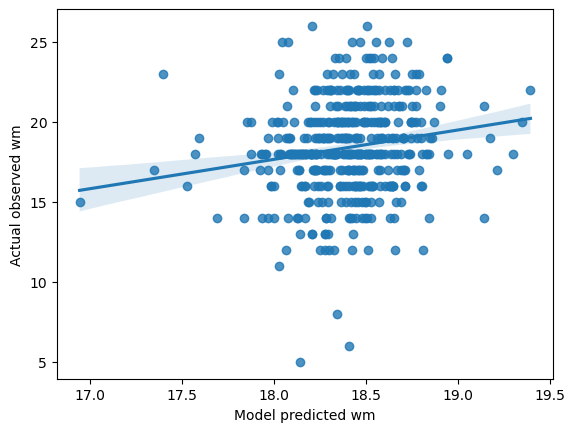

running PCA
transforming data
performing model cross-validation
balancing cross-validation by labels
start balanced cv


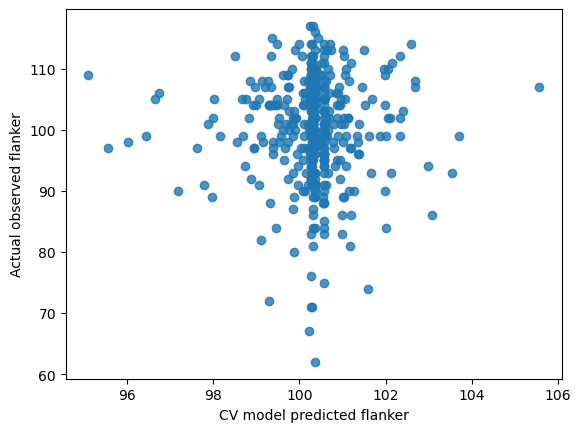

model cv score: r2 =  3.6355084206318063e-06
running final model
final model fit r2 =  0.0627449384420844


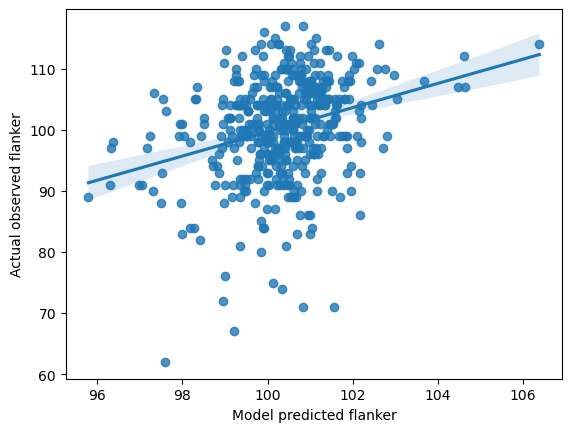

In [79]:
# Run the model for all cog
xp_L = pandas.read_csv(os.path.join(wdir,'G3_CTX_all_L.csv'), header=None)
xp_R = pandas.read_csv(os.path.join(wdir,'G3_CTX_all_R.csv'), header=None)
xp=pandas.concat([xp_L,xp_R,Sex,Site,mFD],axis=1,ignore_index=True)
cogs=['psm', 'dccs', 'wm', 'flanker']
for cog in cogs:
#cog='flanker'   #'psm_adj'    #'dccs_adj'   #'wm_adj'    #'flanker_adj'
    df_cog=df[cog][~df[cog].isna()]
    xp_cog=xp[~df[cog].isna()]
    Age_grp_cog=Age_grp[~df[cog].isna()]
    
    df_cog.index=range(len(df_cog))
    xp_cog.index=range(len(xp_cog))
    Age_grp_cog.index=range(len(Age_grp_cog))
    
    pcalr_out_NEW = hap.PCA_LR_pipeline(xp_cog.values, # X (Gradient Projection)
                                        df_cog, # cog/beh
                                        y_label=cog, #(y label to display)
                                        #pca = None, # use pca or not
                                        #clf = linear_model.LassoCV(random_state=123),
                                        cv_strategy='balanced', #'balanced','score' # Show the 10-fold CV score
                                        illustrative=True, # Show plots
                                        test_gene_num = [1, 2, 5, 10, 20, 50],  # sanity check                                                    
                                        sanity_check_style = None,   # pos. and neg. separate
                                        cv_labels = Age_grp_cog, reverse_axes = False) 
    
    pred_cog=pcalr_out_NEW['final_predicts']
    obs_cog=pcalr_out_NEW['observes']
    pred_obs_cog=pandas.DataFrame({'pred':pred_cog,'obs':obs_cog})
    filename=f"Pred_cog_{cog}_G3.csv"
    pred_obs_cog.to_csv(os.path.join(wdir,filename),index=False)

In [75]:
final_mod=pcalr_out_NEW['final_model']
final_mod.predict()

LassoCV(random_state=123)

In [ ]:
## Run 10-fold cross-validation 10 times
## didnot work correctly because random seed in balanced cv is fixed
# Redoing snippets of the pipeline above
clf = linear_model.LassoCV(random_state = 123) # set LASSO model
pca_tfm = pcalr_out_NEW['pca_object'].transform(xp_cog.values) # perform PCA
cv=10 # 10 rounds
cv_strategy=10 # 10 folds 
y = df_cog
y_label='psm'
cv_labels = Age_grp_cog

score = [] # capture score at each round (just out of interest)
preds = np.zeros((cv_strategy,len(y))) # empty matrix to save predictions

# Run it
for i in range(cv_strategy): # for each round
    # set KFold object
    #sel = model_selection.KFold(n_splits=cv, shuffle=True, random_state=(123 * (i+1)))
    # Make predictions
    #predicted = model_selection.cross_val_predict(clf, xp.values, y=y, cv=sel)
    print('balancing cross-validation by labels')
    observed, predicted = hap.balanced_cv(cv_labels, pca_tfm, y, clf, cv_strategy)    
    # store predictions and scores
    preds[i,:] = predicted
    score.append(stats.pearsonr(predicted, y)[0]**2)
    print('completed iteration',i+1)

# print scores from each round
score

Text(0.5, 1.0, 'Distribution of model weights')

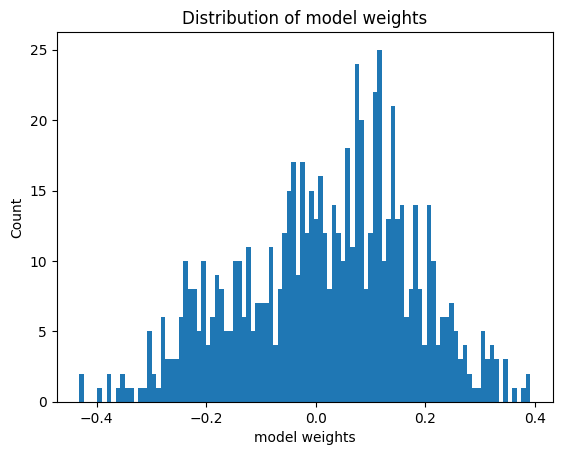

In [310]:
plt.hist(pcalr_out_NEW['betas'],bins=100)
plt.ylabel('Count')
plt.xlabel('model weights')
plt.title('Distribution of model weights') 

In [143]:
np.shape(pcalr_out_NEW['betas'])

(363,)

In [145]:
np.argmax(abs(pcalr_out_NEW['betas']))

26

In [ ]:
#Permutation test
r2_real=pcalr_out_NEW['CV_scores']

perm_num=1000
r2_null=[]

for i in range(perm_num):
    xp_cog_perm=np.random.permutation(xp_cog.values)
    pcalr_out_perm = hap.PCA_LR_pipeline(xp_cog_perm, # X (Gradient Projection)
                        df_cog, # cog/behav
                        y_label=cog, #(y label to display)
                        #pca = None, # use pca or not
                        cv_strategy='balanced', #'balanced','score' # Show the 10-fold CV score                                                                        
                        sanity_check_style = None,   # pos. and neg. separate
                        cv_labels = Age_grp_cog, reverse_axes = False)
    r2_null.append(pcalr_out_perm['CV_scores'])
    

In [ ]:
cog='dccs'   #'psm_adj'    #'dccs_adj'   #'wm_adj'    #'flanker_adj'
df_cog=df[cog][~df[cog].isna()]
xp_cog=xp[~df[cog].isna()]
Age_grp_cog=Age_grp[~df[cog].isna()]

df_cog.index=range(len(df_cog))
xp_cog.index=range(len(xp_cog))
Age_grp_cog.index=range(len(Age_grp_cog))

pcalr_out_dccs = hap.PCA_LR_pipeline(xp_cog.values, # X (Gradient Projection)
                                    df_cog, # cog/beh
                                    y_label=cog, #(y label to display)
                                    #pca = None, # use pca or not
                                    cv_strategy='balanced', #'balanced','score' # Show the 10-fold CV score
                                    illustrative=True, # Show plots
                                    test_gene_num = [1, 2, 5, 10, 20, 50],  # sanity check                                                    
                                    sanity_check_style = None,   # pos. and neg. separate
                                    cv_labels = Age_grp_cog, reverse_axes = False) 

#Permutation test
r2_dccs=pcalr_out_dccs['CV_scores']

perm_num=1000
r2_null_dccs=[]

for i in range(perm_num):
    xp_cog_perm=np.random.permutation(xp_cog.values)
    pcalr_out_perm = hap.PCA_LR_pipeline(xp_cog_perm, # X (Gradient Projection)
                        df_cog, # cog/behav
                        y_label=cog, #(y label to display)
                        #pca = None, # use pca or not
                        cv_strategy='balanced', #'balanced','score' # Show the 10-fold CV score                                                                        
                        sanity_check_style = None,   # pos. and neg. separate
                        cv_labels = Age_grp_cog, reverse_axes = False)
    r2_null_dccs.append(pcalr_out_perm['CV_scores'])

In [ ]:
cog='wm'   #'psm_adj'    #'dccs_adj'   #'wm_adj'    #'flanker_adj'
df_cog=df[cog][~df[cog].isna()]
xp_cog=xp[~df[cog].isna()]
Age_grp_cog=Age_grp[~df[cog].isna()]

df_cog.index=range(len(df_cog))
xp_cog.index=range(len(xp_cog))
Age_grp_cog.index=range(len(Age_grp_cog))

pcalr_out_wm = hap.PCA_LR_pipeline(xp_cog.values, # X (Gradient Projection)
                                    df_cog, # cog/beh
                                    y_label=cog, #(y label to display)
                                    #pca = None, # use pca or not
                                    cv_strategy='balanced', #'balanced','score' # Show the 10-fold CV score
                                    illustrative=True, # Show plots
                                    test_gene_num = [1, 2, 5, 10, 20, 50],  # sanity check                                                    
                                    sanity_check_style = None,   # pos. and neg. separate
                                    cv_labels = Age_grp_cog, reverse_axes = False) 

#Permutation test
r2_wm=pcalr_out_wm['CV_scores']

perm_num=1000
r2_null_wm=[]

for i in range(perm_num):
    xp_cog_perm=np.random.permutation(xp_cog.values)
    pcalr_out_perm = hap.PCA_LR_pipeline(xp_cog_perm, # X (Gradient Projection)
                        df_cog, # cog/behav
                        y_label=cog, #(y label to display)
                        #pca = None, # use pca or not
                        cv_strategy='balanced', #'balanced','score' # Show the 10-fold CV score                                                                        
                        sanity_check_style = None,   # pos. and neg. separate
                        cv_labels = Age_grp_cog, reverse_axes = False)
    r2_null_wm.append(pcalr_out_perm['CV_scores'])

In [ ]:
cog='flanker'   #'psm_adj'    #'dccs_adj'   #'wm_adj'    #'flanker_adj'
df_cog=df[cog][~df[cog].isna()]
xp_cog=xp[~df[cog].isna()]
Age_grp_cog=Age_grp[~df[cog].isna()]

df_cog.index=range(len(df_cog))
xp_cog.index=range(len(xp_cog))
Age_grp_cog.index=range(len(Age_grp_cog))

pcalr_out_flanker = hap.PCA_LR_pipeline(xp_cog.values, # X (Gradient Projection)
                                    df_cog, # cog/beh
                                    y_label=cog, #(y label to display)
                                    #pca = None, # use pca or not
                                    cv_strategy='balanced', #'balanced','score' # Show the 10-fold CV score
                                    illustrative=True, # Show plots
                                    test_gene_num = [1, 2, 5, 10, 20, 50],  # sanity check                                                    
                                    sanity_check_style = None,   # pos. and neg. separate
                                    cv_labels = Age_grp_cog, reverse_axes = False) 

#Permutation test
r2_flanker=pcalr_out_flanker['CV_scores']

perm_num=1000
r2_null_flanker=[]

for i in range(perm_num):
    xp_cog_perm=np.random.permutation(xp_cog.values)
    pcalr_out_perm = hap.PCA_LR_pipeline(xp_cog_perm, # X (Gradient Projection)
                        df_cog, # cog/behav
                        y_label=cog, #(y label to display)
                        #pca = None, # use pca or not
                        cv_strategy='balanced', #'balanced','score' # Show the 10-fold CV score                                                                        
                        sanity_check_style = None,   # pos. and neg. separate
                        cv_labels = Age_grp_cog, reverse_axes = False)
    r2_null_flanker.append(pcalr_out_perm['CV_scores'])

In [350]:
np.mean(r2_real>r2_null)

1.0

In [351]:
np.mean(r2_flanker>r2_null_flanker)

0.293

In [352]:
np.mean(r2_dccs>r2_null_dccs)

0.998

In [353]:
np.mean(r2_wm>r2_null_wm)

0.053